# TimeDiff 聯合條件資料：三項偏差的分層診斷

## 結論
偏差主要出現在模型完整生成後：取樣把真實相關性由 0.335 提高到 0.362，模型輸出卻降至 0.186。個股殘餘變異膨脹至 2.19 倍；high／low 約 21% 超出有效範圍，clipping 造成邊界堆積。尾部目標 1,060 條，跨出 240、跨入 87，最後 907 條。

20／50／100 步的固定噪音對照沒有實質改善；價格重建沒有改變任何尾部分類。這輪沒有重訓或執行 PPO。完整歸因限制與改善順序見同目錄 README.md。

## 方法與資料

分析原 2,000 條、21 日、Dow 10 路徑；條件取自 2010–2017，生成器訓練於 2005–2017。比較原始生成 log return、最終價格反推報酬、配對真實未來及完整條件母體。下列單元會讀取保留的計算表，並從原批次重算關鍵數字；較耗時的模型對照由 `probes.py`、`validation_exact.py`、`trace_solver.py` 留下原始輸出。

### 關鍵限制
重疊視窗與同條件多條路徑相依。96 次抽樣的步數對照、32 條路徑的鏈追蹤皆為固定小型試驗。變異分解描述現象，尚未證明特定訓練改法有效。四條平均不是精確條件期望，不能直接取代隨機生成路徑。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Image
import io
from diagnose import stats
def show_plot(fig):
    buffer=io.BytesIO()
    fig.savefig(buffer,format='png',dpi=150)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)
P=Path.cwd()
summary=json.loads((P/'baseline_summary.json').read_text())
noise=json.loads((P/'noise_and_support.json').read_text())
layers=pd.read_csv(P/'layer_comparison.csv').set_index('source')
cohorts=pd.read_csv(P/'cohort_diagnostics.csv')
solver=pd.read_csv(P/'probes/solver_comparison.csv')
trace=pd.read_csv(P/'reverse_chain_trace.csv')
validation=pd.read_csv(P/'validation_exact_comparison.csv')
plt.rcParams.update({'font.family':'Arial Unicode MS','font.size':11,'axes.unicode_minus':False,
                     'axes.spines.top':False,'axes.spines.right':False})
BLUE,ORANGE,GRAY='#275c96','#b06b22','#9299a3'
z=np.load(P.parent/'dow10_joint_20261017/batch/paths.npz',allow_pickle=False)
recomputed,_=stats(z['raw_features'])
assert len(z['raw_features'])==2000
assert abs(recomputed['corr'].mean()-summary['summary']['corr'])<1e-12
assert int((z['target'][:,0]<=summary['tail']['cutoff']).sum())==1060
assert int((recomputed['return']<=summary['tail']['cutoff']).sum())==907
assert 1060-summary['tail']['lost_tail']+summary['tail']['entered_tail']==907
assert solver.loc[0,'max_abs_replay_error']==0
print('原始陣列的相關性、尾部計數與同種子重現檢查通過。')

原始陣列的相關性、尾部計數與同種子重現檢查通過。


## 結果一：相關性在哪裡下降
相關性定義為每條 21 日路徑中 10 檔股票日 log return 的兩兩相關係數平均，再對路徑取平均。殘餘變異是各股扣除當日所有股票平均報酬後的時間變異。

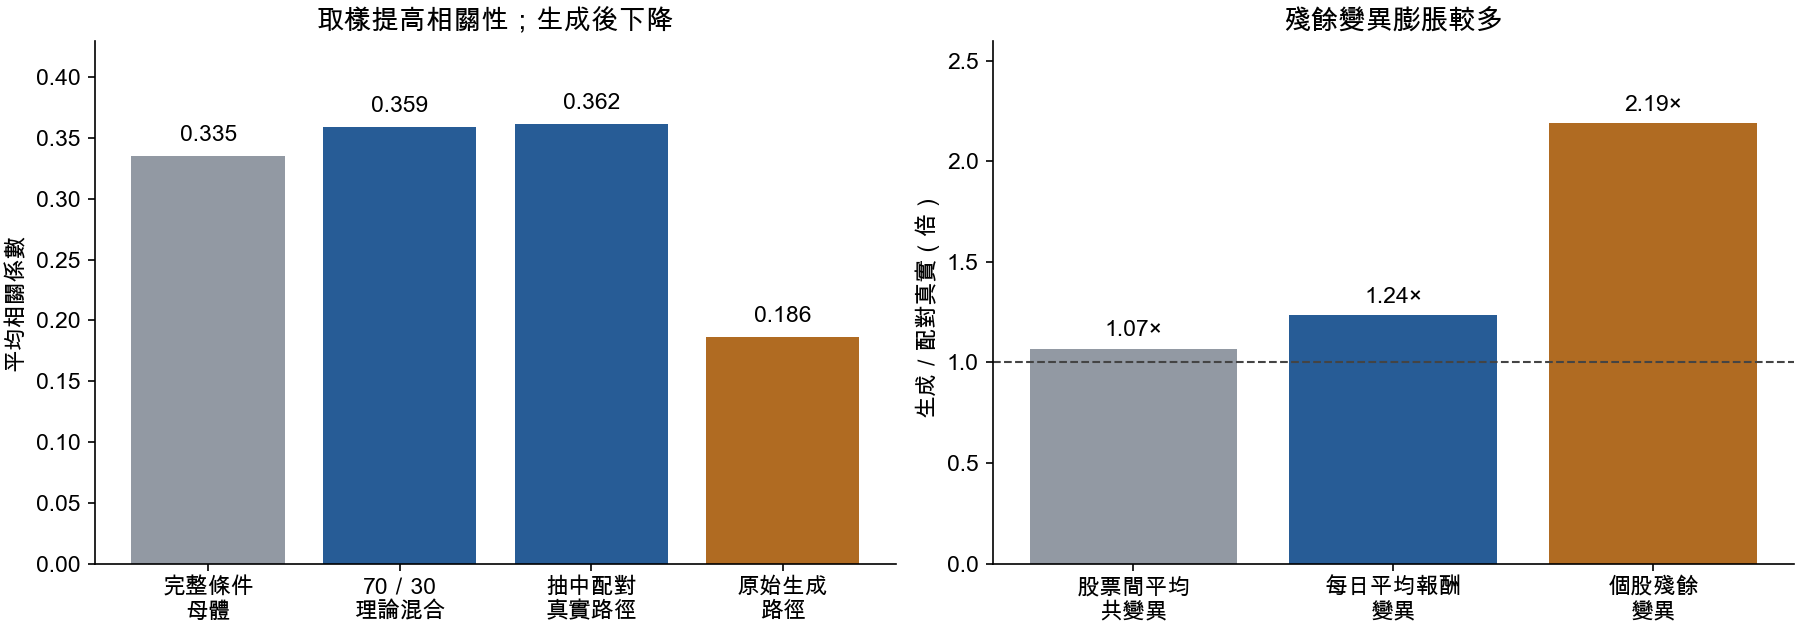

In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
keys=['condition_pool_2010_2017','expected_70_30_mixture','selected_paired_real','generated_raw']
vals=layers.loc[keys,'corr'].to_numpy()
ax[0].bar(range(4),vals,color=[GRAY,BLUE,BLUE,ORANGE])
ax[0].set_xticks(range(4),['完整條件\n母體','70／30\n理論混合','抽中配對\n真實路徑','原始生成\n路徑'])
ax[0].set(ylabel='平均相關係數',ylim=(0,.43),title='取樣提高相關性；生成後下降')
for i,v in enumerate(vals): ax[0].text(i,v+.012,f'{v:.3f}',ha='center')
cols=['mean_offdiag_covariance','common_variance','idiosyncratic_variance']
ratio=layers.loc['generated_raw',cols]/layers.loc['selected_paired_real',cols]
ax[1].bar(range(3),ratio,color=[GRAY,BLUE,ORANGE])
ax[1].set_xticks(range(3),['股票間平均\n共變異','每日平均報酬\n變異','個股殘餘\n變異'])
ax[1].axhline(1,color='#444444',ls='--',lw=1)
ax[1].set(ylabel='生成／配對真實（倍）',ylim=(0,2.6),title='殘餘變異膨脹較多')
for i,v in enumerate(ratio): ax[1].text(i,v+.06,f'{v:.2f}×',ha='center')
fig.savefig(P/'correlation_diagnosis.png',dpi=150)
show_plot(fig)

45 個股票配對的平均相關性全部下降。股票間共變異沒有全面消失，但個股殘餘變異膨脹得更快。這是生成分布的描述性分解；目前 cross-asset loss 未啟用，但尚未做訓練消融，不能斷定只開啟它就會修復。

## 結果二：high／low 的有效範圍與重建副作用
原始 high 特徵需 ≥0，low 特徵需 ≤0。違規率的分母各為 420,000 個股票交易日；不是違規路徑比例。

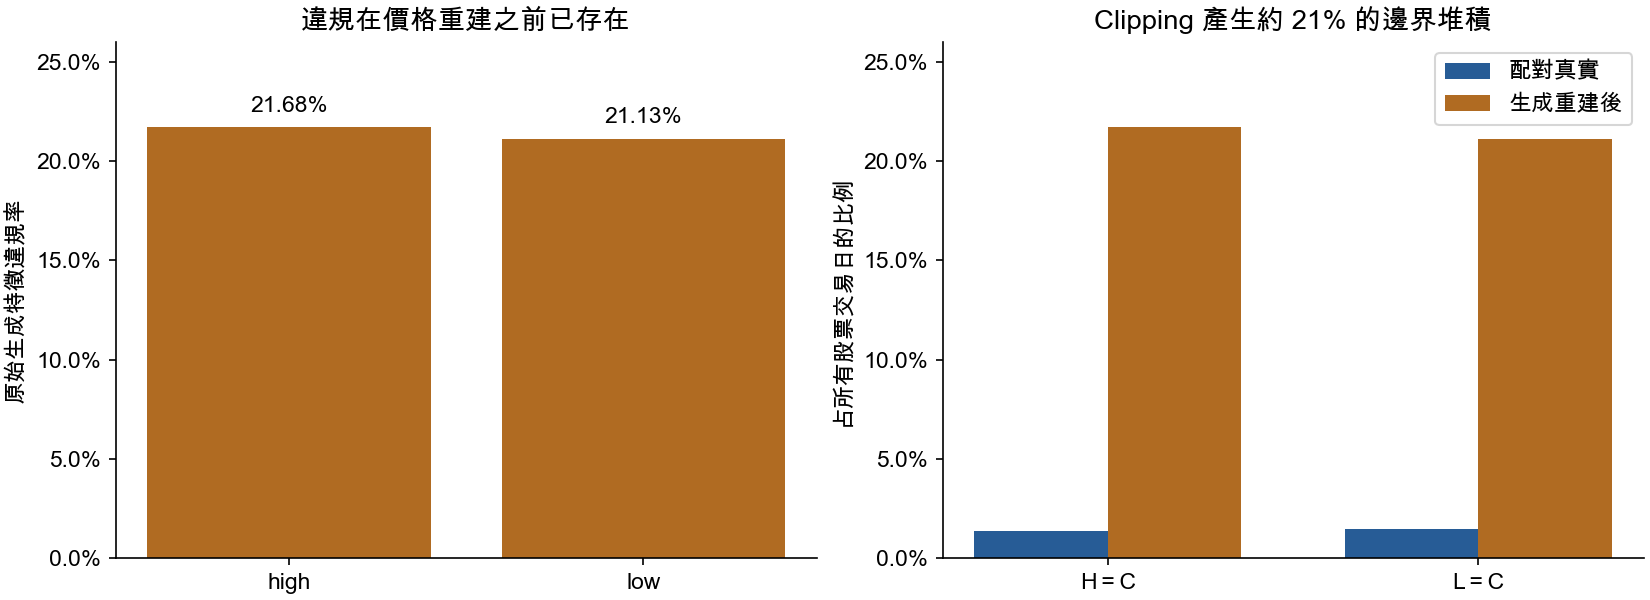

In [3]:
s=pd.DataFrame(noise['support']).set_index('feature')
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
v=s['invalid_fraction'].to_numpy()
ax[0].bar(['high','low'],v,color=ORANGE)
ax[0].set(ylabel='原始生成特徵違規率',ylim=(0,.26),title='違規在價格重建之前已存在')
ax[0].yaxis.set_major_formatter(PercentFormatter(1))
for i,y in enumerate(v): ax[0].text(i,y+.008,f'{y:.2%}',ha='center')
x=np.arange(2)
ax[1].bar(x-.18,s['paired_real_zero_fraction'],.36,label='配對真實',color=BLUE)
ax[1].bar(x+.18,s['generated_final_zero_fraction'],.36,label='生成重建後',color=ORANGE)
ax[1].set_xticks(x,['H＝C','L＝C'])
ax[1].set(ylabel='占所有股票交易日的比例',ylim=(0,.26),title='Clipping 產生約 21% 的邊界堆積')
ax[1].yaxis.set_major_formatter(PercentFormatter(1));ax[1].legend()
fig.savefig(P/'high_low_diagnosis.png',dpi=150)
show_plot(fig)

違規 log 幅度中位數約 0.0046／0.0047，不是浮點誤差。clipping 保證最終價格順序，但讓 H＝C／L＝C 比例大幅升高；它不會改變收盤報酬、相關性或尾部分類。

## 結果三：PR30 門檻附近的條件跨界
門檻為 −0.1841%。尾部是 21 日報酬不高於此值，與「從尾部來源池抽樣」並不相同。

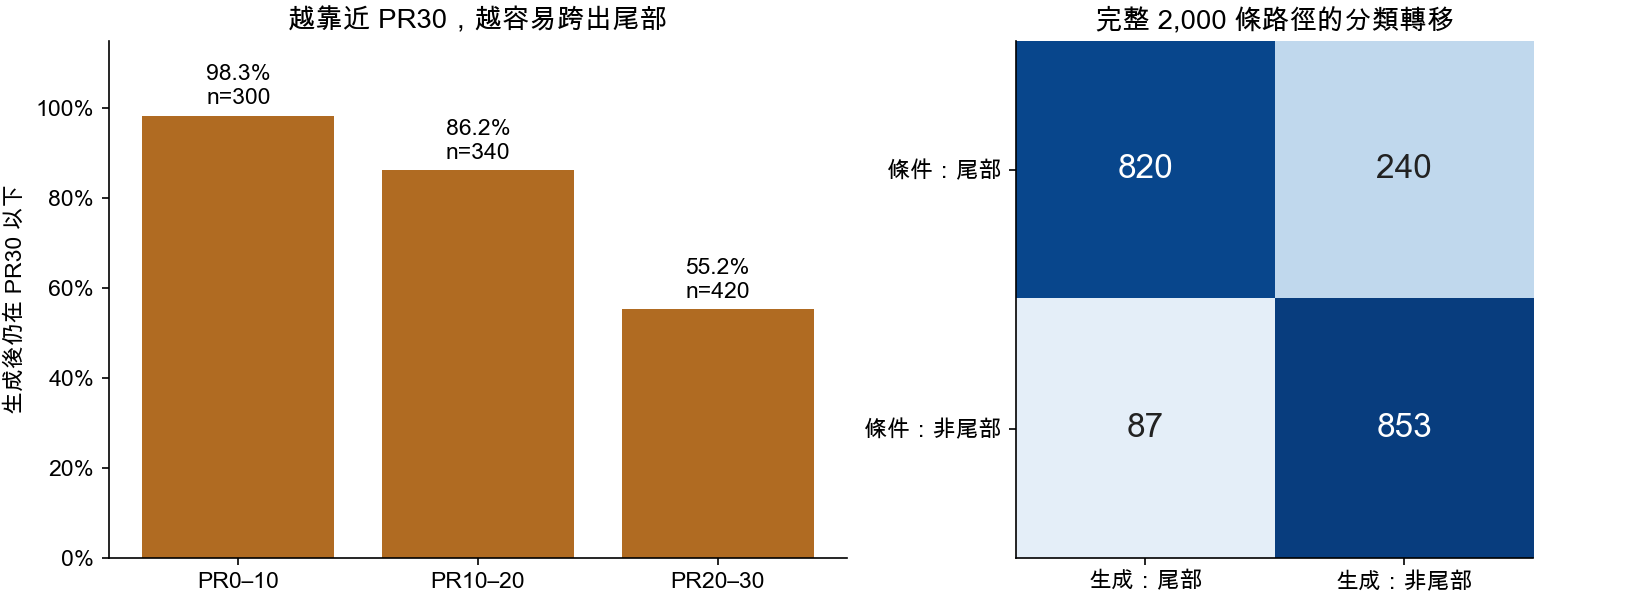

In [4]:
c=cohorts[cohorts.dimension=='target_return_pr'].set_index('group')
labels=['PR0–10','PR10–20','PR20–30']
v=c.loc[labels,'actual_tail'].to_numpy()
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
ax[0].bar(labels,v,color=ORANGE)
ax[0].set(ylabel='生成後仍在 PR30 以下',ylim=(0,1.15),title='越靠近 PR30，越容易跨出尾部')
ax[0].yaxis.set_major_formatter(PercentFormatter(1))
for i,y in enumerate(v):
 ax[0].text(i,y+.025,f'{y:.1%}\nn={int(c.loc[labels[i],"n_paths"])}',ha='center')
matrix=np.array([[820,240],[87,853]])
ax[1].imshow(matrix,cmap='Blues',vmin=0,vmax=900)
ax[1].set_xticks([0,1],['生成：尾部','生成：非尾部'])
ax[1].set_yticks([0,1],['條件：尾部','條件：非尾部'])
ax[1].set_title('完整 2,000 條路徑的分類轉移')
for i in range(2):
 for j in range(2): ax[1].text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>500 else '#222222',fontsize=16)
fig.savefig(P/'tail_diagnosis.png',dpi=150)
show_plot(fig)

240 條跨出、87 條跨入，淨少 153 條。跨出者有 188 條來自 PR20–30；240 條中有 90% 的目標距門檻不超過 2 個百分點。報酬誤差標準差 1.984 個百分點，遠大於平均偏差 0.119 個百分點；扣掉全體平均偏差仍只得到 46.6% 的尾部占比。

## 模型對照：增加生成步數是否有效
以下固定原先隨機打散計畫的前 96 次抽樣，每次 4 條。兩個種子分別比較 20／100 步；第一種子另做 50 步。子集目標尾部占比為 55.21%。

In [5]:
display(solver[['seed','sampling_steps','corr','high_invalid','low_invalid','actual_tail','return_mae']].rename(columns={
 'seed':'噪音種子','sampling_steps':'生成步數','corr':'相關性','high_invalid':'high 違規率',
 'low_invalid':'low 違規率','actual_tail':'尾部占比','return_mae':'報酬 MAE'}).round(4))

,噪音種子,生成步數,相關性,high 違規率,low 違規率,尾部占比,報酬 MAE
0,20261018,20,0.1858,0.2126,0.2124,0.4792,0.0157
1,20261018,50,0.1860,0.2132,0.2126,0.4792,0.0156
2,20261018,100,0.1856,0.2133,0.2125,0.4792,0.0157
3,20261019,20,0.1872,0.2162,0.2125,0.4453,0.0151
4,20261019,100,0.1870,0.2166,0.2127,0.4453,0.0151


數值步數增加沒有實質改善。下一圖追蹤原批次第一個 batch 的 32 條路徑，每一點為當下 denoiser 的 clean-data 預測；最後一點才是 sampler 回傳結果。這不是完整 2,000 條的平均。

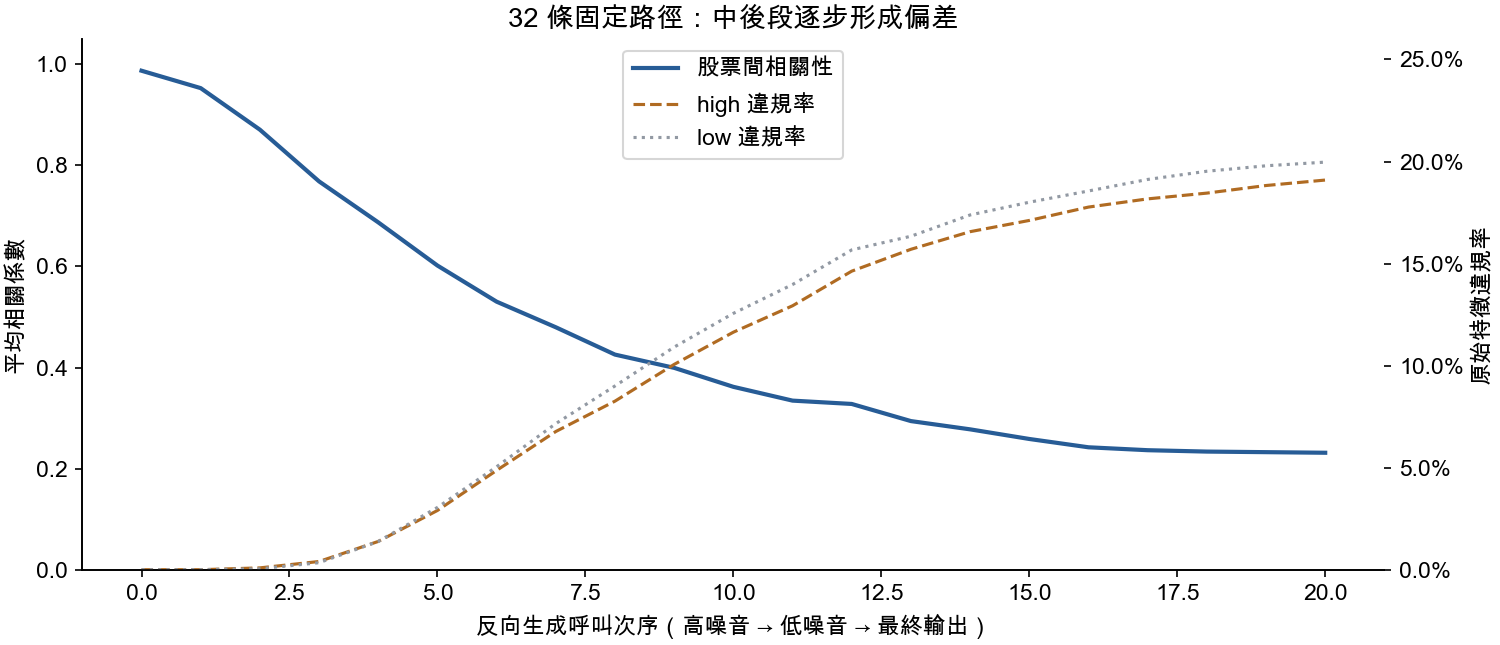

In [6]:
fig,ax=plt.subplots(figsize=(10,4.3),constrained_layout=True)
ax.plot(trace['call'],trace['corr'],color=BLUE,label='股票間相關性',lw=2)
ax.set(xlabel='反向生成呼叫次序（高噪音 → 低噪音 → 最終輸出）',ylabel='平均相關係數',ylim=(0,1.05),title='32 條固定路徑：中後段逐步形成偏差')
other=ax.twinx()
other.plot(trace['call'],trace['high_invalid'],color=ORANGE,label='high 違規率',ls='--')
other.plot(trace['call'],trace['low_invalid'],color=GRAY,label='low 違規率',ls=':')
other.set(ylabel='原始特徵違規率',ylim=(0,.26));other.yaxis.set_major_formatter(PercentFormatter(1))
lines=ax.get_lines()+other.get_lines();ax.legend(lines,[l.get_label() for l in lines],loc='upper center')
fig.savefig(P/'reverse_chain_diagnosis.png',dpi=150)
show_plot(fig)

單步高噪音輸出反而過度相關、幾乎沒有 high／low 違規，完整生成後才出現問題。因此不宜只用高 t 的單步輸出設計或驗證修正。完整鏈追蹤逐位元重現原始輸出；介入只有觀測，未改變模型結果。

## 完整驗證期重查
沿用原 DataLoader、seed 1729，先精確重現前 128 個視窗分數，再延伸到全部 483 個視窗。另一份手動 tensor batching 的結果使用不同噪音流，未用於這項比較。

In [7]:
audit=json.loads((P/'validation_exact_audit.json').read_text())
assert abs(audit['recorded_mse']-audit['replayed_first128_mse'])<1e-7
display(validation[['group','n_paths','standardized_condition_mse','corr','high_invalid','low_invalid']].round(4))

,group,n_paths,standardized_condition_mse,corr,high_invalid,low_invalid
0,original_first_128,128,0.1492,0.2311,0.1949,0.1729
1,remaining_355,355,0.1112,0.1801,0.2084,0.1880
2,all_483,483,0.1213,0.1936,0.2048,0.1840


## 改善順序
1. **P0 評估**：用完整或跨年固定驗證子集、多種子與多個 checkpoints，評估最終生成的條件、共變異、個股波動、high／low 支持範圍及多樣性。
2. **P1 跨股票結構**：先驗證對共同／殘餘變異及最終生成統計的約束；避免只在 t=99 的單步輸出加相關性 loss。
3. **P1 high／low**：重訓時改用非負幅度表示，包含真實零值處理；不直接對舊輸出套 softplus。
4. **P2 條件一致性**：固定 70／30，對照生成末端條件約束及權重，特別看 PR20–30 的跨界；不得只追求平均尾部比率而犧牲多樣性。

目前不優先增加尾部配額、平移全部報酬、剔除生成樣本或增加 solver 步數。完整驗證 MSE 未惡化，所以尚不能把問題定為選錯 checkpoint；較確定的是原本選模指標忽略了結構品質。以上是待驗證方案，尚未訓練驗證其效果。